#### Charts

If `data/processed/` is empty, first run `uv run python -m src.data` from the project folder.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, next(str(p) for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()))   # project folder: makes src importable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter, PercentFormatter
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

from src.data import load

daily, intraday, sentiment = load("daily"), load("intraday_1m"), load("sentiment")
full_name = {t.split()[0]: t for t in daily["ticker"].cat.categories}  # "AAPL" -> "AAPL UW Equity"

def price(ticker):
    """PX_LAST of a ticker indexed by date: the short name ("AAPL") or the full one ("AAPL UW Equity") both work."""
    short = ticker.split()[0]
    if short not in full_name:
        raise ValueError(f"ticker not in the daily data: {ticker}")
    return daily.loc[daily["ticker"] == full_name[short]].set_index("date")["PX_LAST"].rename(short)

# 8 colours in a fixed order, distinguishable also by colour-blind readers, and neutral colours for text, grid and axes
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE, REFERENCE = PALETTE[0], "#9a9992"
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
LW = 1.5
compact = FuncFormatter(lambda v, _: f"{v / 1e6:,.0f}M" if v >= 1e6 else f"{v / 1e3:,.0f}K" if v >= 1e3 else f"{v:,.0f}")
percent = PercentFormatter(1, decimals=0)
# sequential scale (a single blue, from light to dark) for the heatmaps
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

def style(ax, title):
    ax.set_facecolor(SURFACE)
    ax.set_title(title, loc="left", color=INK, fontsize=11, pad=10)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(which="both", colors=MUTED, labelsize=9, length=0)

def minute_axis(ax, index):
    """Converts the times (datetime.time) to minutes from midnight, with a label for each hour."""
    ticks = range(10 * 60, 16 * 60 + 1, 60)
    ax.set_xticks(ticks, [f"{m // 60}:00" for m in ticks])
    return [t.hour * 60 + t.minute for t in index]

sentiment: 347 placeholders -134217.7 converted to NaN


#### Data overview

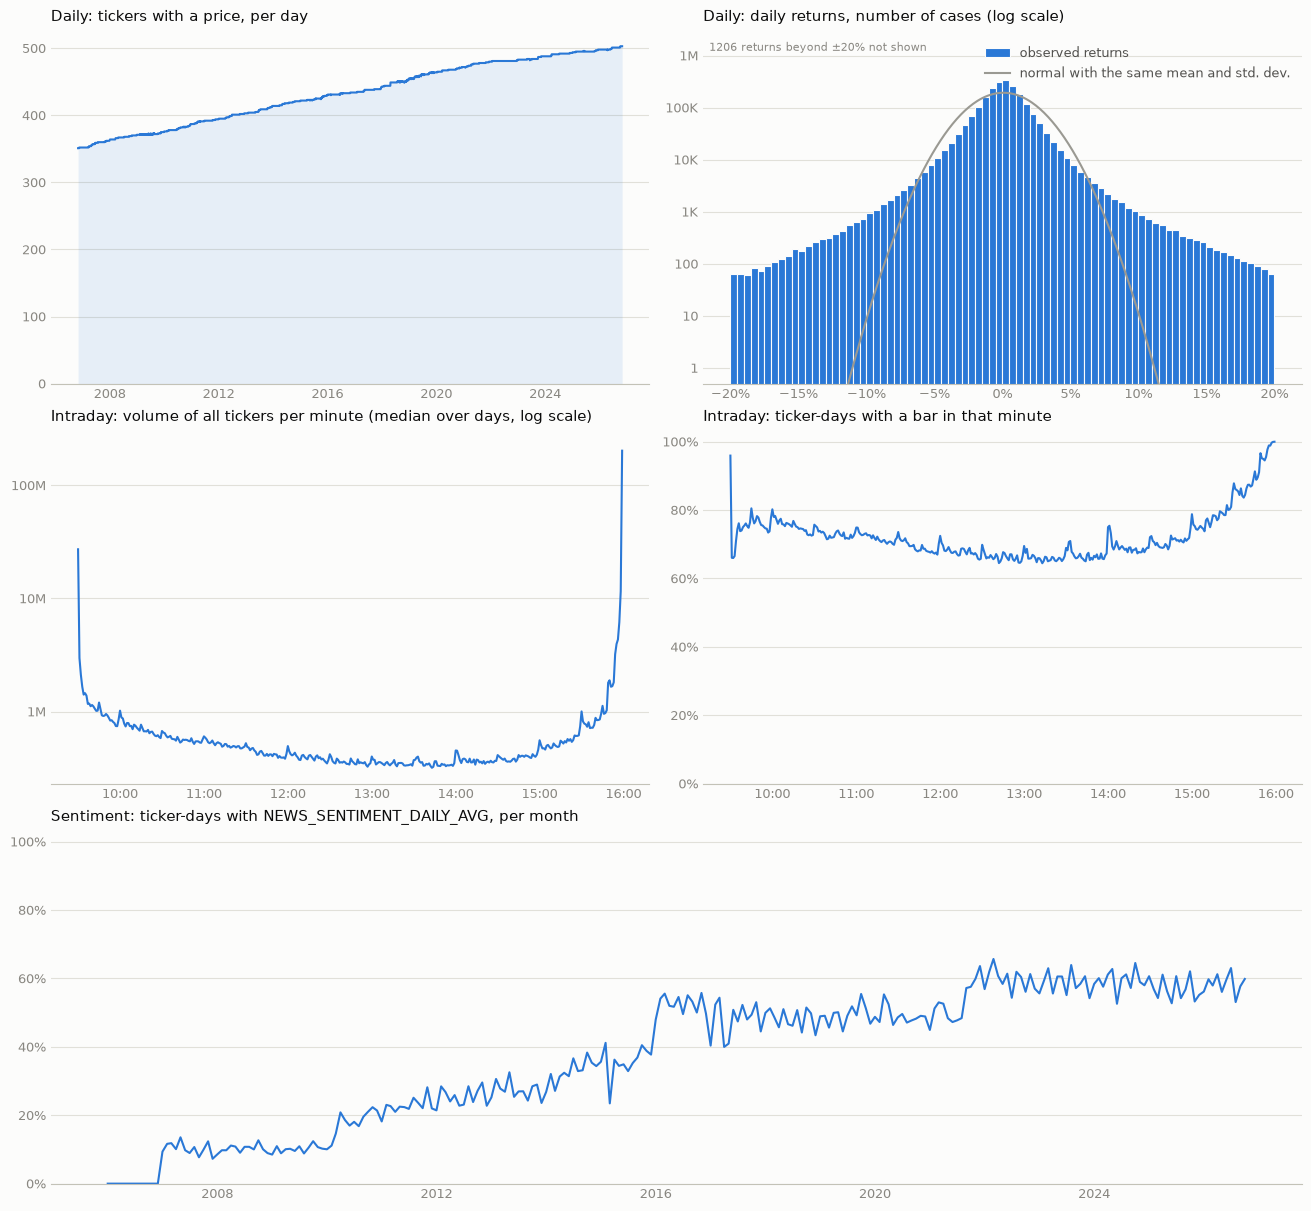

In [2]:
fig, axes = plt.subplot_mosaic(
    [["coverage", "returns"], ["volume", "bars"], ["sentiment", "sentiment"]],
    figsize=(13, 12), facecolor=SURFACE, layout="constrained")

# 1. the universe is today's index members: whoever joined after 2006 is missing at the start
ax = axes["coverage"]
coverage = daily.dropna(subset=["PX_LAST"]).groupby("date").size()
ax.plot(coverage.index, coverage.values, color=BLUE, lw=LW)
ax.fill_between(coverage.index, coverage.values, color=BLUE, alpha=0.1, lw=0)
ax.set_ylim(0, 520)
style(ax, "Daily: tickers with a price, per day")

# 2. fat tails: extreme returns are much more frequent than in a normal distribution
ax = axes["returns"]
r = daily["ret"].dropna()  # computed by load(): only between consecutive trading days
bins = np.linspace(-0.2, 0.2, 81)
ax.hist(r[r.abs() <= 0.2], bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.8, label="observed returns")
x = np.linspace(-0.2, 0.2, 400)
normal = len(r) * (bins[1] - bins[0]) * np.exp(-0.5 * ((x - r.mean()) / r.std()) ** 2) / (r.std() * np.sqrt(2 * np.pi))
ax.plot(x, normal, color=REFERENCE, lw=LW, label="normal with the same mean and std. dev.")
ax.set_yscale("log")
ax.set_ylim(0.5, None)
ax.yaxis.set_major_formatter(compact)
ax.xaxis.set_major_formatter(percent)
ax.legend(frameon=False, labelcolor=INK_2, fontsize=9, loc="upper right")
ax.text(0.01, 0.98, f"{(r.abs() > 0.2).sum()} returns beyond ±20% not shown", transform=ax.transAxes, va="top", color=MUTED, fontsize=8)
style(ax, "Daily: daily returns, number of cases (log scale)")

# 3. profile of the day: high volume at the open and at the close
#    the first and last minute contain the opening and closing auctions: without a log scale they would flatten the rest
ax = axes["volume"]
volume = intraday.groupby(["date", "time"], observed=True)["volume"].sum().groupby(level="time", observed=True).median()
ax.plot(minute_axis(ax, volume.index), volume.values, color=BLUE, lw=LW)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(compact)
style(ax, "Intraday: volume of all tickers per minute (median over days, log scale)")

# 4. completeness: in which minutes the most bars are missing
ax = axes["bars"]
present = intraday.groupby("time", observed=True).size() / intraday.groupby(["ticker", "date"], observed=True).ngroups
ax.plot(minute_axis(ax, present.index), present.values, color=BLUE, lw=LW)
ax.set_ylim(0, 1.02)
ax.yaxis.set_major_formatter(percent)
style(ax, "Intraday: ticker-days with a bar in that minute")

# 5. sentiment coverage over time, complete months only (after the last trading day the file is empty)
ax = axes["sentiment"]
s = sentiment[sentiment["date"] < daily["date"].max().replace(day=1)]
covered = s["NEWS_SENTIMENT_DAILY_AVG"].notna().groupby(s["date"].dt.to_period("M")).mean()
ax.plot(covered.index.to_timestamp(), covered.values, color=BLUE, lw=LW)
ax.set_ylim(0, 1.02)
ax.yaxis.set_major_formatter(percent)
style(ax, "Sentiment: ticker-days with NEWS_SENTIMENT_DAILY_AVG, per month")

plt.show()

#### Price comparison

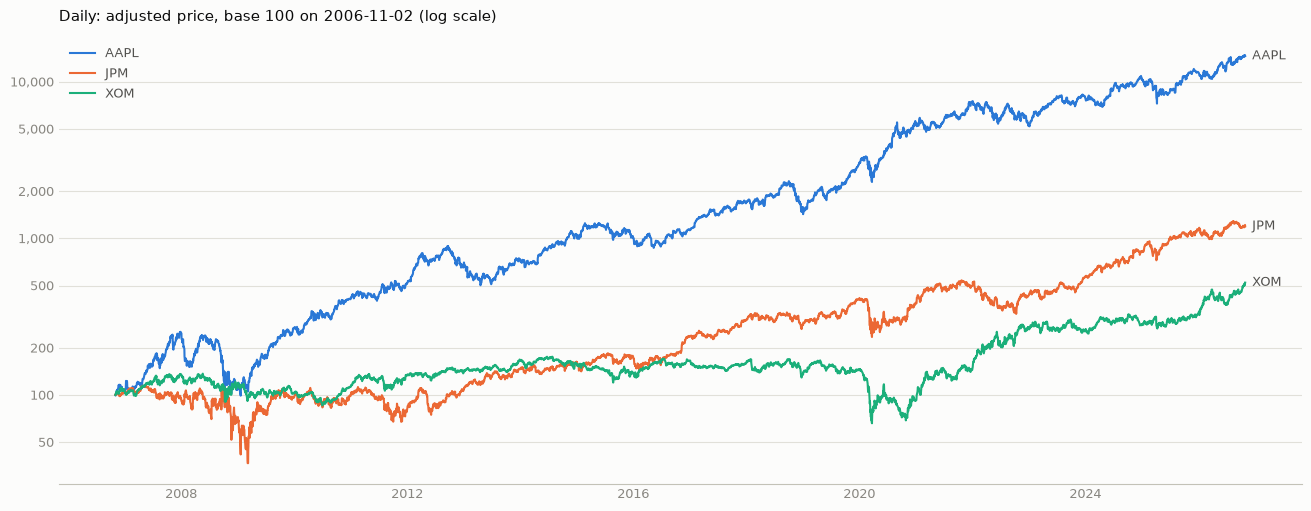

In [3]:
# tickers to compare: change the list and rerun the cell
# the short name ("AAPL") or the full one ("AAPL UW Equity") both work; at most 8, one per palette colour
TICKERS = ["AAPL", "JPM", "XOM"]

if len(TICKERS) > len(PALETTE):
    raise ValueError(f"at most {len(PALETTE)} tickers, one per palette colour")

# base 100 on the first day on which all have a price, so tickers that joined later are comparable
prices = pd.concat([price(t) for t in TICKERS], axis=1)
start = prices.dropna().index[0]
prices = prices.loc[start:] / prices.loc[start] * 100

fig, ax = plt.subplots(figsize=(13, 5), facecolor=SURFACE, layout="constrained")
for (name, s), color in zip(prices.items(), PALETTE):
    ax.plot(s.index, s.values, color=color, lw=LW, label=name)  # holes in the series stay as breaks in the line
    last = s.dropna()
    ax.annotate(name, (last.index[-1], last.iloc[-1]), xytext=(5, 0), textcoords="offset points", va="center", color=INK_2, fontsize=9)
ax.set_yscale("log")
ax.yaxis.set_major_locator(LogLocator(subs=(1, 2, 5)))  # labels at 1, 2, 5, 10, 20, 50...
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_minor_formatter(NullFormatter())
ax.legend(frameon=False, labelcolor=INK_2, fontsize=9, loc="upper left")
style(ax, f"Daily: adjusted price, base 100 on {start.date()} (log scale)")
plt.show()

#### Pair explorer

KO/PEP: 34 trades, exits {'stop': 27, 'end of window': 4, 'convergence': 3}


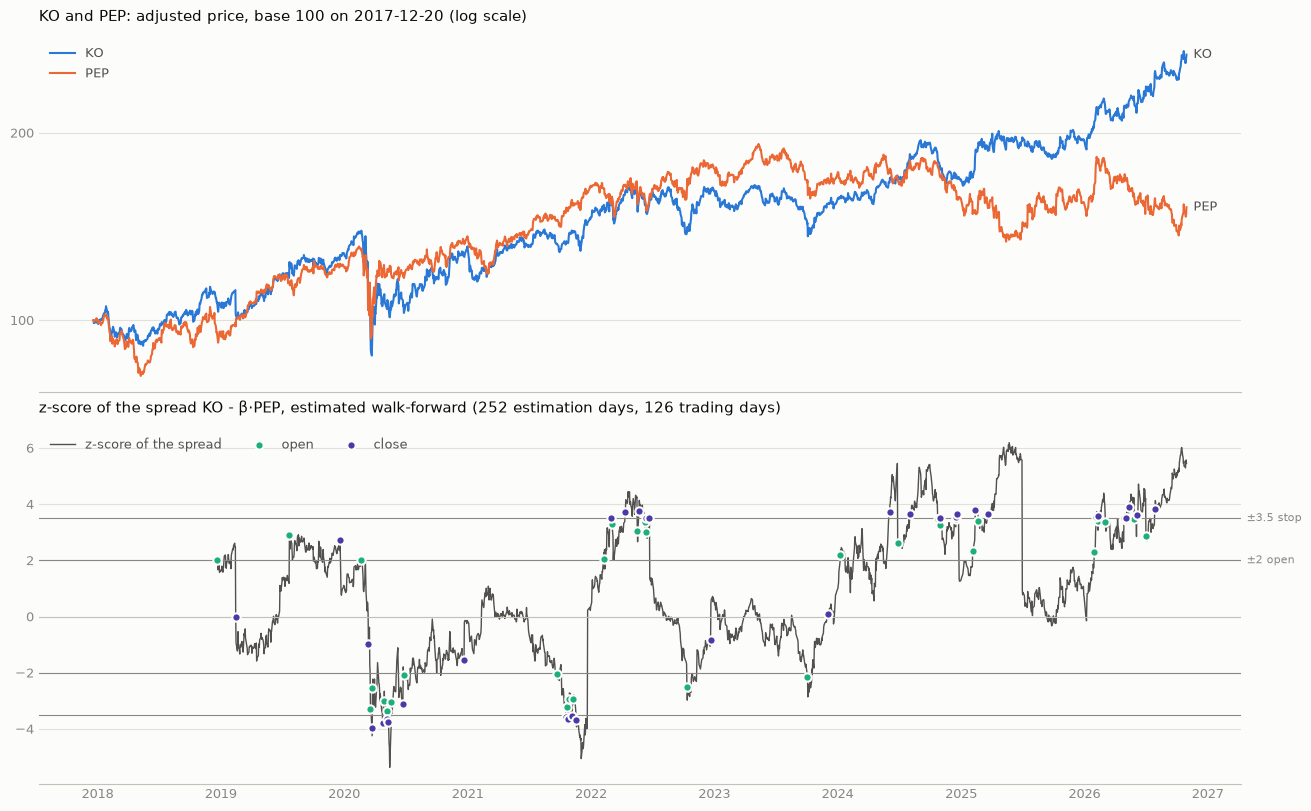

In [4]:
# pair to explore: change the two tickers and rerun the cell
PAIR = ("KO", "PEP")
FORMATION, TRADING = 252, 126      # trading days: 12 months to estimate, 6 to trade (SPEC, decision 6)
ENTRY, EXIT, STOP = 2.0, 0.0, 3.5  # thresholds on the z-score of the spread (SPEC, decision 5)

logp = np.log(pd.concat([price(t) for t in PAIR], axis=1).dropna())
a, b = logp.columns
if len(logp) <= FORMATION:
    raise ValueError(f"{a} and {b} have only {len(logp)} days in common: more than {FORMATION} are needed")

# walk-forward: hedge ratio (OLS of log a on log b), mean and std. dev. of the spread are estimated on the previous
# 12 months and applied to the next 6, so the z-score of a day uses no future information
z = pd.Series(np.nan, index=logp.index)
window_end = set()
for start in range(FORMATION, len(logp), TRADING):
    formation, trading = logp.iloc[start - FORMATION:start], logp.iloc[start:start + TRADING]
    beta = np.polyfit(formation[b], formation[a], 1)[0]
    spread = formation[a] - beta * formation[b]
    z.iloc[start:start + TRADING] = (trading[a] - beta * trading[b] - spread.mean()) / spread.std()
    window_end.add(trading.index[-1])

# trades: open when |z| goes beyond ENTRY (sell the spread if z > 0, buy it if z < 0); close when z goes back to EXIT,
# when |z| reaches STOP or at the end of the window, because the next window has another hedge ratio
trades, position = [], 0
for day, value in z.dropna().items():
    if position == 0:
        if ENTRY < abs(value) < STOP and day not in window_end:
            position, opened = -np.sign(value), day
        continue
    if abs(value) >= STOP:
        reason = "stop"
    elif position * value >= -EXIT:
        reason = "convergence"
    elif day in window_end:
        reason = "end of window"
    else:
        continue
    trades.append((opened, day, reason))
    position = 0
trades = pd.DataFrame(trades, columns=["open", "close", "exit"])
print(f"{a}/{b}: {len(trades)} trades, exits {trades['exit'].value_counts().to_dict()}")

fig, (top, bottom) = plt.subplots(2, 1, figsize=(13, 8), sharex=True, facecolor=SURFACE, layout="constrained")

prices = np.exp(logp - logp.iloc[0]) * 100
for name, color in zip(prices, PALETTE):
    top.plot(prices.index, prices[name], color=color, lw=LW, label=name)
    top.annotate(name, (prices.index[-1], prices[name].iloc[-1]), xytext=(5, 0), textcoords="offset points", va="center", color=INK_2, fontsize=9)
top.set_yscale("log")
top.yaxis.set_major_locator(LogLocator(subs=(1, 2, 5)))
top.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
top.yaxis.set_minor_formatter(NullFormatter())
top.legend(frameon=False, labelcolor=INK_2, fontsize=9, loc="upper left")
style(top, f"{a} and {b}: adjusted price, base 100 on {prices.index[0].date()} (log scale)")

bottom.plot(z.index, z.values, color=INK_2, lw=1, label="z-score of the spread")
for level in [-STOP, -ENTRY, ENTRY, STOP]:
    bottom.axhline(level, color=MUTED, lw=0.8)
bottom.axhline(EXIT, color=AXIS, lw=0.8)
for level, label in [(ENTRY, "open"), (STOP, "stop")]:
    bottom.annotate(f"±{level:g} {label}", (1, level), xycoords=("axes fraction", "data"), xytext=(4, 0), textcoords="offset points", va="center", color=MUTED, fontsize=8)
bottom.scatter(trades["open"], z[trades["open"]], s=36, color=PALETTE[2], edgecolor=SURFACE, linewidth=1.5, zorder=3, label="open")
bottom.scatter(trades["close"], z[trades["close"]], s=36, color=PALETTE[6], edgecolor=SURFACE, linewidth=1.5, zorder=3, label="close")
bottom.legend(frameon=False, labelcolor=INK_2, fontsize=9, loc="upper left", ncols=3)
style(bottom, f"z-score of the spread {a} - β·{b}, estimated walk-forward ({FORMATION} estimation days, {TRADING} trading days)")
plt.show()

#### Correlations between stocks

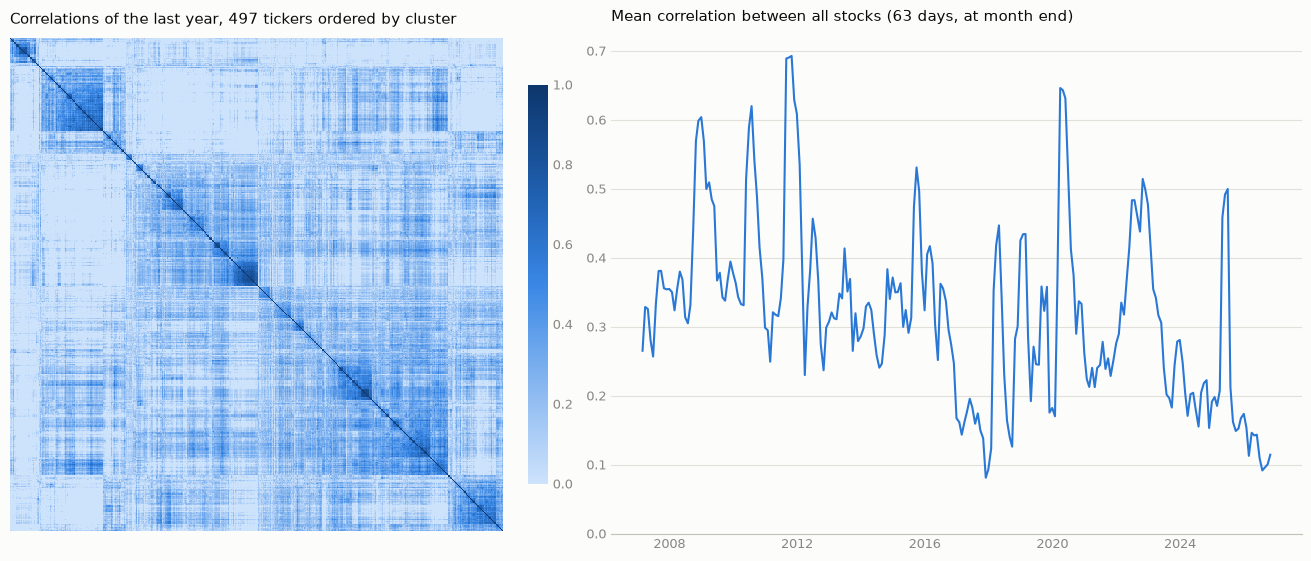

,,correlation
ticker 1,ticker 2,
GOOG,GOOGL,0.996
FOX,FOXA,0.985
NWS,NWSA,0.962
NSC,UNP,0.943
CPT,MAA,0.924
DHI,PHM,0.920
AMAT,LRCX,0.907
MTB,RF,0.901
DOW,LYB,0.900


In [5]:
# daily returns with one column per ticker (short name), computed by load() only between consecutive days
returns = daily.pivot(index="date", columns="ticker", values="ret").dropna(how="all")  # the first day has no returns
returns.columns = [t.split()[0] for t in returns.columns]

# correlations of the last year between the tickers with at least 90% of the days, reordered by hierarchical clustering
# (distance = 1 - correlation): similar stocks end up close and form blocks, i.e. families of candidates
WINDOW = 252
recent = returns.iloc[-WINDOW:].dropna(axis=1, thresh=int(0.9 * WINDOW))
corr = recent.corr()
order = leaves_list(linkage(squareform(1 - corr.to_numpy(), checks=False), method="average"))
corr = corr.iloc[order, order]

# mean correlation between all stocks over the last 63 days (a quarter), at every month end:
# when it rises for everyone (crises) stocks move together and divergences between pairs say less
avg_corr = {}
for day in returns.index.to_series().groupby(returns.index.to_period("M")).last():
    window = returns.loc[:day].iloc[-63:].dropna(axis=1)
    if len(window) == 63:
        c = np.corrcoef(window.to_numpy().T)
        avg_corr[day] = np.nanmean(c[np.triu_indices(len(c), k=1)])
avg_corr = pd.Series(avg_corr)

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5.5), width_ratios=[1, 1.4], facecolor=SURFACE, layout="constrained")
image = left.imshow(corr, cmap=BLUES, vmin=0, vmax=1, interpolation="nearest")  # the few negative correlations are shown as 0
left.set_xticks([])
left.set_yticks([])
for side in left.spines.values():
    side.set_visible(False)
left.set_title(f"Correlations of the last year, {len(corr)} tickers ordered by cluster", loc="left", color=INK, fontsize=11, pad=10)
colorbar = fig.colorbar(image, ax=left, shrink=0.8)
colorbar.outline.set_visible(False)
colorbar.ax.tick_params(colors=MUTED, labelsize=9, length=0)

right.plot(avg_corr.index, avg_corr.values, color=BLUE, lw=LW)
right.set_ylim(0, None)
style(right, "Mean correlation between all stocks (63 days, at month end)")
plt.show()

# the most correlated pairs of the last year, to look at in the explorer above
# (high correlation is not enough: the pair must then be tested for cointegration)
top_pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna().nlargest(10)
display(top_pairs.rename_axis(["ticker 1", "ticker 2"]).round(3).to_frame("correlation"))

#### News and price moves

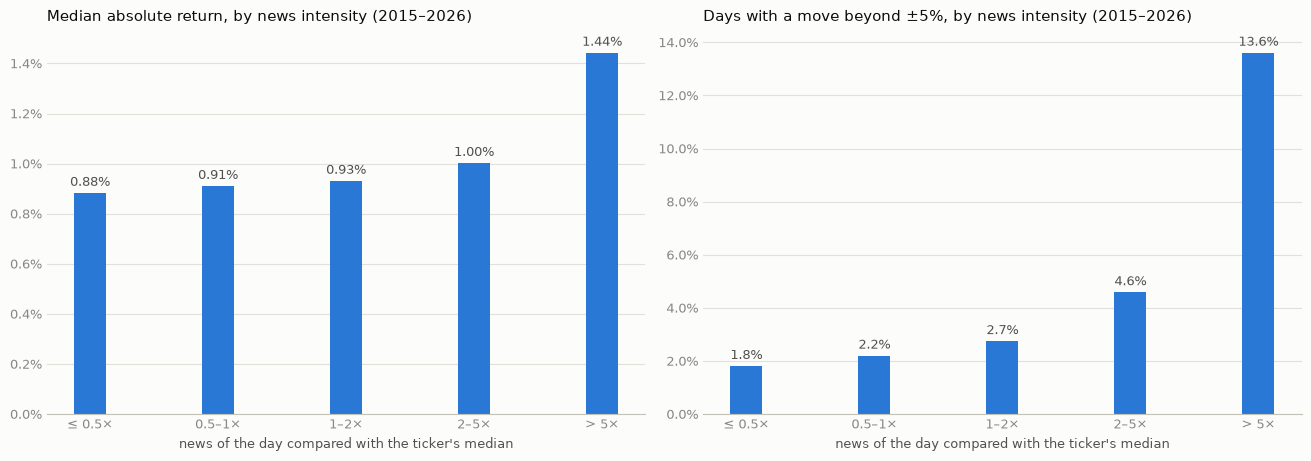

In [6]:
# on days with many news compared with what is usual for that stock, are the moves larger?
# the comparison is within each ticker (news of the day / median of the ticker), so a stock always on the front page does not dominate
# careful: it does not say what causes what, a big move also produces news
news = daily[["ticker", "date", "ret"]].merge(sentiment[["ticker", "date", "NEWS_PUBLICATION_COUNT"]], on=["ticker", "date"]).dropna()
typical = news.groupby("ticker", observed=True)["NEWS_PUBLICATION_COUNT"].transform("median").clip(lower=1)
news["bucket"] = pd.cut(news["NEWS_PUBLICATION_COUNT"] / typical, [-np.inf, 0.5, 1, 2, 5, np.inf],
                        labels=["≤ 0.5×", "0.5–1×", "1–2×", "2–5×", "> 5×"])
stats = news.groupby("bucket", observed=True)["ret"].agg(
    median=lambda r: r.abs().median(), beyond_5=lambda r: (r.abs() > 0.05).mean())

period = f"{news['date'].min().year}–{news['date'].max().year}"
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), facecolor=SURFACE, layout="constrained")
for ax, column, title, fmt in zip(axes, stats, ["Median absolute return", "Days with a move beyond ±5%"], ["{:.2%}", "{:.1%}"]):
    bars = ax.bar(stats.index.astype(str), stats[column], color=BLUE, width=0.25)
    ax.bar_label(bars, labels=[fmt.format(v) for v in stats[column]], color=INK_2, fontsize=9, padding=3)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
    ax.set_xlabel("news of the day compared with the ticker's median", color=INK_2, fontsize=9)
    style(ax, f"{title}, by news intensity ({period})")
plt.show()